In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data=[]

data_dir_path = "../outputs"
for filename in os.listdir(data_dir_path):
    if filename.endswith(".json"):
        file_path = os.path.join(data_dir_path, filename)

        with open(file_path, "r", encoding="utf-8") as f:
            content = json.load(f)
            data.append(content)

print(f"loaded {len(data)} files")

loaded 39 files


In [2]:
output_file = "processed_data.json"
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=2)

In [3]:
with open("processed_data.json", "r") as f:
    data = json.load(f)

rows = []

for item in data:
    row = {}

    # -----------------------
    # 1. RUN INFO (6 cols)
    # -----------------------
    run = item.get("run_info", {})
    row["topic_1"] = run.get("topic_1")
    row["topic_2"] = run.get("topic_2")
    row["stratum"] = run.get("stratum")
    row["question_type"] = run.get("question_type")
    row["scenario_retry_count"] = run.get("scenario_retry_count", {})
    row["question_retry_count"] = run.get("question_retry_count", {})

    # -----------------------
    # 2. SCENARIO (7 cols)
    # -----------------------
    scenario = item.get("top_scenario", {})
    dim_s = scenario.get("dimension_scores", {})

    row["domain"] = scenario.get("domain")
    row["scenario_overall_score"] = scenario.get("overall_score")  # renamed
    row["learning_objective_fidelity"] = dim_s.get("learning_objective_fidelity")
    row["scenario_cognitive_load_balance"] = dim_s.get("cognitive_load_balance")  # renamed
    row["numerical_fertility"] = dim_s.get("numerical_fertility")
    row["conceptual_depth"] = dim_s.get("conceptual_depth")
    row["domain_coherence_scenario"] = dim_s.get("domain_coherence")

    # -----------------------
    # 3. QUESTION (6 cols)
    # -----------------------
    question = item.get("best_question", {})
    dim_q = question.get("dimension_scores", {})

    row["question_overall_score"] = question.get("overall_score")
    row["learning_objective_reflection"] = dim_q.get("learning_objective_reflection")
    row["question_cognitive_load_balance"] = dim_q.get("cognitive_load_balance")
    row["decomposability"] = dim_q.get("decomposability")
    row["domain_coherence_question"] = dim_q.get("domain_coherence")
    row["boundary_adherence"] = dim_q.get("boundary_adherence")

    # -----------------------
    # 4. STUDENT AGENT (4 cols)
    # -----------------------
    student = item.get("student_attempt", {})
    solv = student.get("solvability", {})

    row["student_confidence"] = student.get("student_confidence")
    row["has_enough_context"] = solv.get("has_enough_context")
    row["attemptable_within_knowledge"] = solv.get("attemptable_within_knowledge")
    row["solvable"] = solv.get("solvable")

    # -----------------------
    # 5. TOKENS (12 cols)
    # -----------------------
    tokens = item.get("token_usage", {}).get("per_node", {})

    def get_tokens(node):
        return (
            tokens.get(node, {}).get("input_tokens"),
            tokens.get(node, {}).get("output_tokens"),
        )

    row["scenario_generator_input_tokens"], row["scenario_generator_output_tokens"] = get_tokens("scenario_generator")
    row["scenario_evaluator_input_tokens"], row["scenario_evaluator_output_tokens"] = get_tokens("scenario_evaluator")
    row["question_type_classifier_input_tokens"], row["question_type_classifier_output_tokens"] = get_tokens("question_type_classifier")
    row["question_generator_input_tokens"], row["question_generator_output_tokens"] = get_tokens("question_generator")
    row["student_agent_input_tokens"], row["student_agent_output_tokens"] = get_tokens("student_agent")
    row["pedagogical_prior_evaluator_input_tokens"], row["pedagogical_prior_evaluator_output_tokens"] = get_tokens("pedagogical_prior_evaluator")

    rows.append(row)

# Create DataFrame
df = pd.DataFrame(rows)
df["id"]=df.index

# -----------------------
# FINAL CHECK
# -----------------------
print("Shape:", df.shape)  # should be (n, 35)
df.head()

Shape: (39, 36)


,topic_1,topic_2,stratum,question_type,scenario_retry_count,question_retry_count,domain,scenario_overall_score,learning_objective_fidelity,scenario_cognitive_load_balance,...,scenario_evaluator_output_tokens,question_type_classifier_input_tokens,question_type_classifier_output_tokens,question_generator_input_tokens,question_generator_output_tokens,student_agent_input_tokens,student_agent_output_tokens,pedagogical_prior_evaluator_input_tokens,pedagogical_prior_evaluator_output_tokens,id
0,vector_spaces_and_subspaces,determinants_and_invertibility,same,mixed,0,1,Finance,0.84,0.9,0.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,conditional_probability,variance_and_standard_deviation,same,mixed,0,0,Finance,0.85,0.9,0.8,...,421.0,426.0,48.0,452.0,861.0,964.0,1628.0,2749.0,382.0,1
2,eigenvalues_and_eigenvectors,covariance_matrix,same,mixed,0,3,Astrophysics,0.83,0.9,0.8,...,393.0,446.0,71.0,4994.0,2835.0,3690.0,4824.0,1404.0,179.0,2
3,least_squares_regression,differential_equations_odes,adjacent,mixed,0,0,Engineering,0.88,0.9,0.8,...,418.0,447.0,66.0,473.0,718.0,1006.0,1353.0,2068.0,312.0,3
4,determinants_and_invertibility,variance_and_standard_deviation,distant,mixed,0,0,Biomedical Engineering,0.82,0.9,0.8,...,399.0,443.0,59.0,469.0,628.0,892.0,1316.0,1752.0,254.0,4


In [4]:
df.describe()

,scenario_retry_count,question_retry_count,scenario_overall_score,learning_objective_fidelity,scenario_cognitive_load_balance,numerical_fertility,conceptual_depth,domain_coherence_scenario,question_overall_score,learning_objective_reflection,...,scenario_evaluator_output_tokens,question_type_classifier_input_tokens,question_type_classifier_output_tokens,question_generator_input_tokens,question_generator_output_tokens,student_agent_input_tokens,student_agent_output_tokens,pedagogical_prior_evaluator_input_tokens,pedagogical_prior_evaluator_output_tokens,id
count,39.0,39.000000,39.000000,3.900000e+01,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,...,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,39.000000
mean,0.0,0.717949,0.838974,9.000000e-01,0.810256,0.858974,0.728205,0.894872,0.812692,0.848718,...,389.470588,454.617647,66.205882,1493.882353,1167.205882,1550.823529,2325.294118,1972.676471,281.294118,19.000000
std,0.0,0.971941,0.022454,2.249473e-16,0.030735,0.058345,0.055954,0.022346,0.044778,0.050637,...,28.876157,31.613207,10.227057,1465.596823,698.857847,875.164797,1289.932216,637.556496,120.786195,11.401754
min,0.0,0.000000,0.800000,9.000000e-01,0.800000,0.700000,0.700000,0.800000,0.740000,0.800000,...,329.000000,404.000000,48.000000,430.000000,474.000000,759.000000,1009.000000,1309.000000,148.000000,0.000000
25%,0.0,0.000000,0.820000,9.000000e-01,0.800000,0.800000,0.700000,0.900000,0.795000,0.800000,...,371.000000,436.000000,59.500000,483.500000,688.500000,931.250000,1329.750000,1504.000000,179.500000,9.500000
50%,0.0,0.000000,0.840000,9.000000e-01,0.800000,0.900000,0.700000,0.900000,0.825000,0.800000,...,387.500000,452.000000,64.500000,514.500000,845.500000,1044.500000,1849.500000,1780.500000,270.000000,19.000000
75%,0.0,1.000000,0.840000,9.000000e-01,0.800000,0.900000,0.700000,0.900000,0.850000,0.900000,...,403.750000,470.500000,71.000000,1946.250000,1443.250000,1852.250000,2860.750000,2320.000000,342.000000,28.500000
max,0.0,3.000000,0.900000,9.000000e-01,0.900000,0.950000,0.900000,0.900000,0.875000,0.900000,...,469.000000,550.000000,103.000000,5694.000000,3055.000000,3693.000000,6277.000000,4121.000000,689.000000,38.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 36 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   topic_1                                    39 non-null     str    
 1   topic_2                                    39 non-null     str    
 2   stratum                                    39 non-null     str    
 3   question_type                              39 non-null     str    
 4   scenario_retry_count                       39 non-null     int64  
 5   question_retry_count                       39 non-null     int64  
 6   domain                                     39 non-null     str    
 7   scenario_overall_score                     39 non-null     float64
 8   learning_objective_fidelity                39 non-null     float64
 9   scenario_cognitive_load_balance            39 non-null     float64
 10  numerical_fertility                    

In [6]:
df.columns

Index(['topic_1', 'topic_2', 'stratum', 'question_type',
       'scenario_retry_count', 'question_retry_count', 'domain',
       'scenario_overall_score', 'learning_objective_fidelity',
       'scenario_cognitive_load_balance', 'numerical_fertility',
       'conceptual_depth', 'domain_coherence_scenario',
       'question_overall_score', 'learning_objective_reflection',
       'question_cognitive_load_balance', 'decomposability',
       'domain_coherence_question', 'boundary_adherence', 'student_confidence',
       'has_enough_context', 'attemptable_within_knowledge', 'solvable',
       'scenario_generator_input_tokens', 'scenario_generator_output_tokens',
       'scenario_evaluator_input_tokens', 'scenario_evaluator_output_tokens',
       'question_type_classifier_input_tokens',
       'question_type_classifier_output_tokens',
       'question_generator_input_tokens', 'question_generator_output_tokens',
       'student_agent_input_tokens', 'student_agent_output_tokens',
       'pedago

In [32]:
# total tokens per agent
df["scenario_generator_total_tokens"]=(df["scenario_generator_input_tokens"] + df["scenario_generator_output_tokens"])
df["scenario_evaluator_total_tokens"]=(df["scenario_evaluator_input_tokens"] + df["scenario_evaluator_output_tokens"])
df["question_type_classifier_total_tokens"]=(df["question_type_classifier_input_tokens"] + df["question_type_classifier_output_tokens"])
df["question_generator_total_tokens"]=(df["question_generator_input_tokens"]+df["question_generator_output_tokens"])
df["student_agent_total_tokens"]=(df["student_agent_input_tokens"]+ df["student_agent_output_tokens"])
df["pedagogical_prior_evaluator_total_tokens"]=(df["pedagogical_prior_evaluator_input_tokens"] + df["pedagogical_prior_evaluator_output_tokens"])
df["total_input_tokens"] = df.filter(like="_input_tokens").sum(axis=1)
df["total_output_tokens"] = df.filter(like="_output_tokens").sum(axis=1)
df["total_retry"]=(df["scenario_retry_count"] + df["question_retry_count"])

In [29]:
# contribution percentage(%) per agent
df["scenario_generator_percentage"]=(df["scenario_generator_total_tokens"]/df["total_input_tokens"])
df["scenario_evaluator_percentage"]=(df["scenario_evaluator_total_tokens"]/df["total_input_tokens"])
df["question_type_classifier_percentage"]=(df["question_type_classifier_total_tokens"]/df["total_input_tokens"])
df["question_generator_percentage"]=(df["question_generator_total_tokens"]/df["total_input_tokens"])
df["student_agent_percentage"]=(df["student_agent_total_tokens"]/df["total_input_tokens"])
df["pedagogical_prior_evaluator_percentage"]=(df["pedagogical_prior_evaluator_total_tokens"]/df["total_input_tokens"])

In [33]:
# input vs output ratio per agent
df["scenario_generator_io_ratio"]=(df["scenario_generator_output_tokens"] / df["scenario_generator_input_tokens"])
df["scenario_evaluator_io_ratio"]=(df["scenario_evaluator_output_tokens"] / df["scenario_evaluator_input_tokens"])
df["question_type_classifier_io_ratio"]=(df["question_type_classifier_output_tokens"] / df["question_type_classifier_input_tokens"])
df["question_generator_io_ratio"]=(df["question_generator_output_tokens"] / df["question_generator_input_tokens"])
df["student_agent_io_ratio"]=(df["student_agent_output_tokens"] / df["student_agent_input_tokens"])
df["pedagogical_prior_evaluator_io_ratio"]=(df["pedagogical_prior_evaluator_output_tokens"] / df["pedagogical_prior_evaluator_input_tokens"])

In [17]:
tokens_df=df[["id","scenario_generator_input_tokens", 
              "scenario_generator_output_tokens", "scenario_evaluator_input_tokens", "scenario_evaluator_output_tokens", 
              "question_type_classifier_input_tokens", "question_type_classifier_output_tokens", "question_generator_input_tokens",
              "question_generator_output_tokens", "student_agent_input_tokens", "student_agent_output_tokens", "pedagogical_prior_evaluator_input_tokens",
              "pedagogical_prior_evaluator_output_tokens", "total_input_tokens", "total_output_tokens", "scenario_generator_total_tokens", "scenario_evaluator_total_tokens",
              "question_generator_total_tokens", "student_agent_total_tokens", "pedagogical_prior_evaluator_total_tokens"]]
tokens_df=tokens_df.dropna()
tokens_df.head()

,id,scenario_generator_input_tokens,scenario_generator_output_tokens,scenario_evaluator_input_tokens,scenario_evaluator_output_tokens,question_type_classifier_input_tokens,question_type_classifier_output_tokens,question_generator_input_tokens,question_generator_output_tokens,student_agent_input_tokens,student_agent_output_tokens,pedagogical_prior_evaluator_input_tokens,pedagogical_prior_evaluator_output_tokens,total_input_tokens,total_output_tokens,scenario_generator_total_tokens,scenario_evaluator_total_tokens,question_generator_total_tokens,student_agent_total_tokens,pedagogical_prior_evaluator_total_tokens
1,1,515.0,801.0,1217.0,421.0,426.0,48.0,452.0,861.0,964.0,1628.0,2749.0,382.0,6323.0,4141.0,1316.0,1638.0,1313.0,2592.0,3131.0
2,2,510.0,805.0,1213.0,393.0,446.0,71.0,4994.0,2835.0,3690.0,4824.0,1404.0,179.0,12257.0,9107.0,1315.0,1606.0,7829.0,8514.0,1583.0
3,3,508.0,878.0,1284.0,418.0,447.0,66.0,473.0,718.0,1006.0,1353.0,2068.0,312.0,5786.0,3745.0,1386.0,1702.0,1191.0,2359.0,2380.0
4,4,489.0,886.0,1292.0,399.0,443.0,59.0,469.0,628.0,892.0,1316.0,1752.0,254.0,5337.0,3542.0,1375.0,1691.0,1097.0,2208.0,2006.0
5,5,487.0,896.0,1300.0,403.0,447.0,73.0,2166.0,1275.0,1815.0,2874.0,1418.0,181.0,7633.0,5702.0,1383.0,1703.0,3441.0,4689.0,1599.0


<Figure size 1200x400 with 0 Axes>

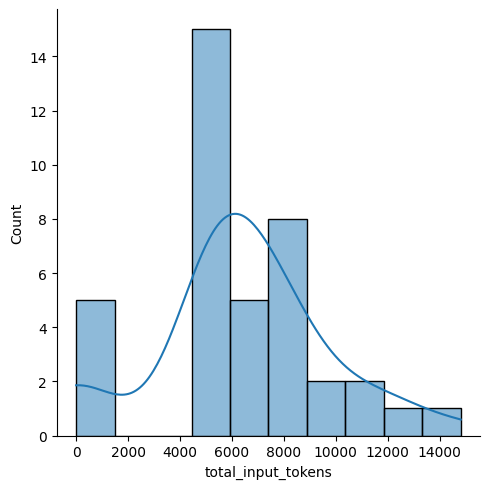

In [10]:
plt.figure(figsize=(12,4))
sns.displot(data=df, x="total_input_tokens", kde=True)
# plt.xlabel("")

<Axes: xlabel='total_input_tokens', ylabel='total_output_tokens'>

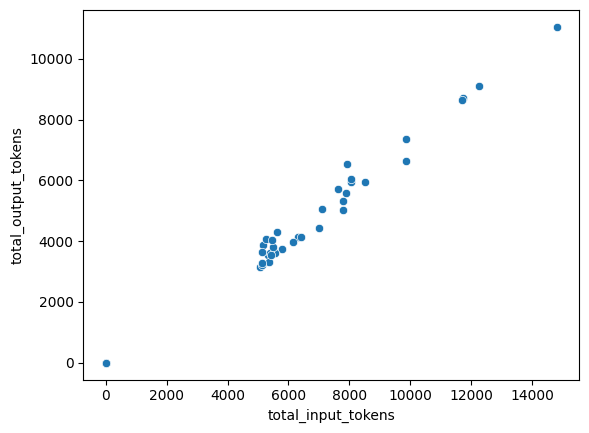

In [11]:
sns.scatterplot(data=df, x="total_input_tokens", y="total_output_tokens")

In [12]:
corr = np.corrcoef(df["total_output_tokens"], df["total_retry"])
corr

array([[1.        , 0.55260796],
       [0.55260796, 1.        ]])

In [13]:
df["stratum"].value_counts()

stratum
same        14
distant     13
adjacent    12
Name: count, dtype: int64

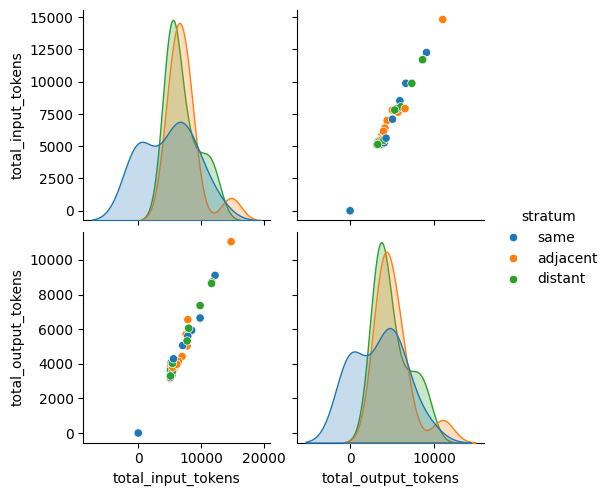

In [14]:
sns.pairplot(df[["total_input_tokens", "total_output_tokens", "stratum"]], hue="stratum")

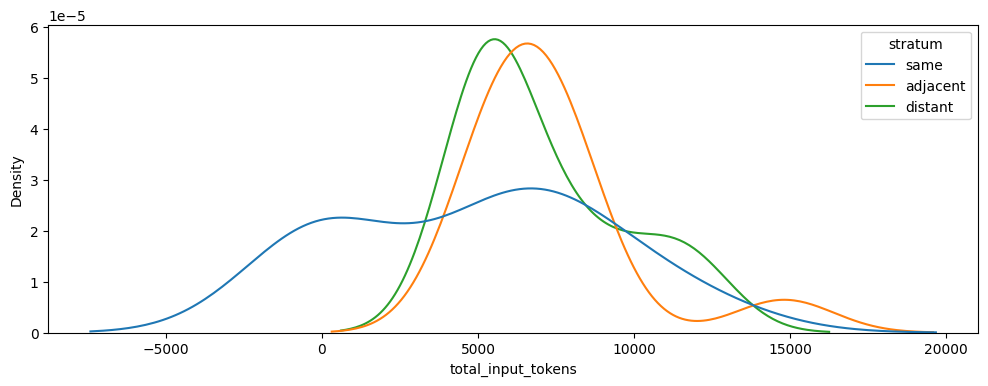

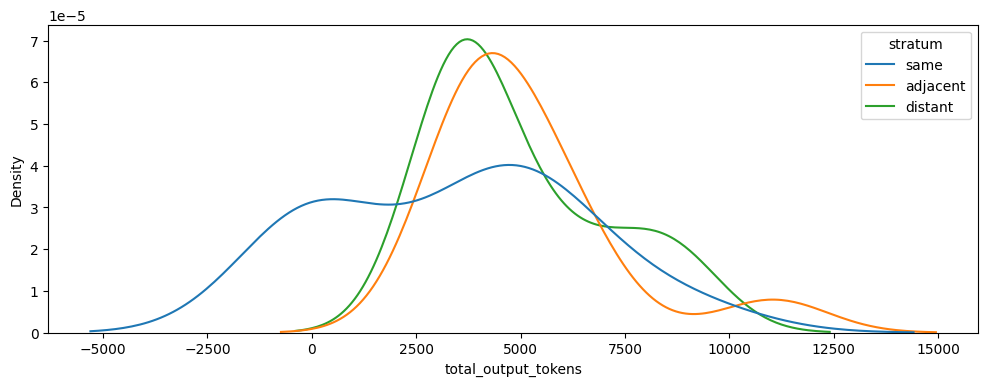

In [15]:
plt.figure(figsize=(12,4))
# plt.title("")
sns.kdeplot(df, x="total_input_tokens", hue="stratum")
plt.xlabel("total_input_tokens")
plt.show()

plt.figure(figsize=(12,4))
# plt.title("")
sns.kdeplot(df, x="total_output_tokens", hue="stratum")
plt.xlabel("total_output_tokens")
plt.show()


In [16]:
df["total_input_tokens"].describe()

count       39.000000
mean      6339.897436
std       3356.654646
min          0.000000
25%       5214.000000
50%       5786.000000
75%       7907.000000
max      14817.000000
Name: total_input_tokens, dtype: float64

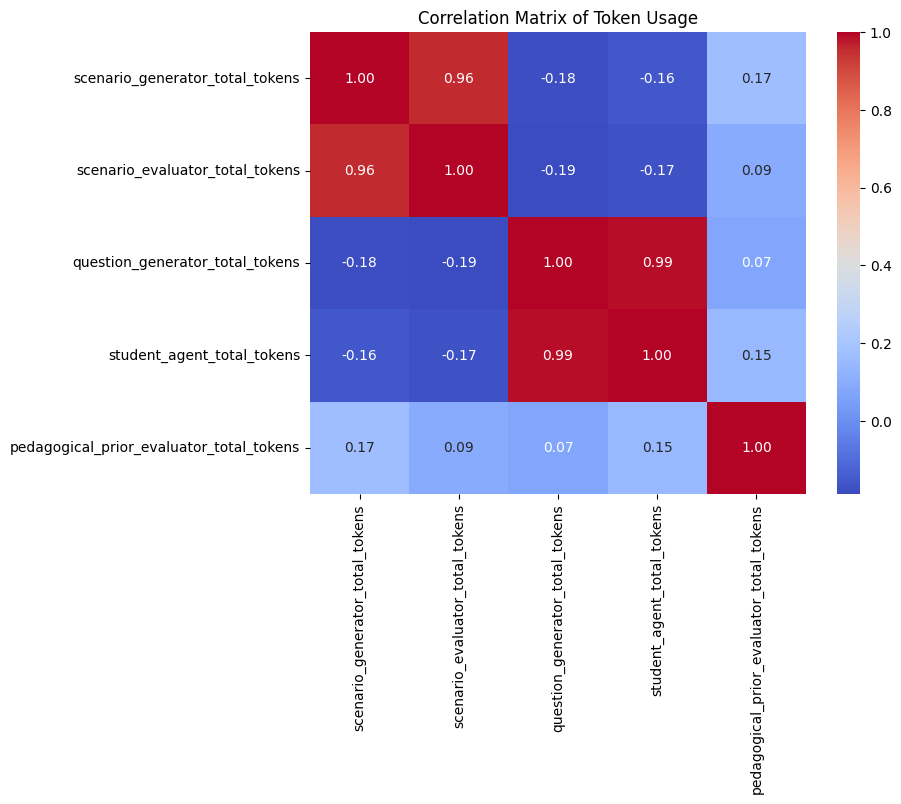

In [28]:
# correlation matrix for token usage is completely meaningless.

corr = tokens_df[["scenario_generator_total_tokens", "scenario_evaluator_total_tokens",
              "question_generator_total_tokens", "student_agent_total_tokens", "pedagogical_prior_evaluator_total_tokens"]].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Token Usage")
plt.show()

In [35]:
df[["scenario_generator_io_ratio", "scenario_evaluator_io_ratio", "question_type_classifier_io_ratio","question_generator_io_ratio", "student_agent_io_ratio", "pedagogical_prior_evaluator_io_ratio"]].mean()

scenario_generator_io_ratio             1.786076
scenario_evaluator_io_ratio             0.300721
question_type_classifier_io_ratio       0.145520
question_generator_io_ratio             1.112449
student_agent_io_ratio                  1.514294
pedagogical_prior_evaluator_io_ratio    0.139370
dtype: float64

# Ratio Insights
## Conclusion from above mean ratio Analysis:
- Scenario generator prompt: Experiment by removing `steps: []` to reduce output tokens.
- Question generator prompt:, remove `expected_concepts:[]` and also `parameters:{}`. Comparatively, there is not more effect than scenario generator and student agent.
- Student Agent Prompt: 



# Comprehensive EDA (Extended)
This section adds a structured, cell-by-cell exploratory data analysis pipeline.
Each block below covers a different EDA angle with visual evidence.

In [36]:
# Standard plotting setup for all following EDA cells
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

eda_df = df.copy()

# Basic sanitation for numeric operations
numeric_cols = eda_df.select_dtypes(include=[np.number]).columns.tolist()
for col in numeric_cols:
    eda_df[col] = pd.to_numeric(eda_df[col], errors="coerce")

print("Rows, Columns:", eda_df.shape)
print("Numeric columns:", len(numeric_cols))

Rows, Columns: (39, 56)
Numeric columns: 48


In [37]:
# 1) Data quality report: nulls, duplicates, unique counts
quality_report = pd.DataFrame({
    "dtype": eda_df.dtypes.astype(str),
    "null_count": eda_df.isna().sum(),
    "null_pct": (eda_df.isna().mean() * 100).round(2),
    "n_unique": eda_df.nunique(dropna=True)
}).sort_values("null_pct", ascending=False)

print("Duplicate rows:", eda_df.duplicated().sum())
quality_report.head(20)

Duplicate rows: 0


,dtype,null_count,null_pct,n_unique
scenario_generator_input_tokens,float64,5,12.82,25
scenario_generator_io_ratio,float64,5,12.82,34
scenario_evaluator_io_ratio,float64,5,12.82,34
student_agent_percentage,float64,5,12.82,34
scenario_generator_percentage,float64,5,12.82,34
scenario_evaluator_percentage,float64,5,12.82,34
question_generator_percentage,float64,5,12.82,34
student_agent_io_ratio,float64,5,12.82,34
pedagogical_prior_evaluator_total_tokens,float64,5,12.82,34
student_agent_total_tokens,float64,5,12.82,33


## EDA Block 1: Feature Engineering

In [38]:
# Derived features for richer EDA
eda_df = df.copy()

# Guard against divide-by-zero in ratio features
eps = 1e-9

eda_df["total_tokens"] = eda_df["total_input_tokens"] + eda_df["total_output_tokens"]
eda_df["output_to_input_ratio"] = eda_df["total_output_tokens"] / (eda_df["total_input_tokens"] + eps)
eda_df["retry_rate"] = eda_df["total_retry"] / (eda_df["total_tokens"] + eps)

eda_df["scenario_efficiency"] = eda_df["scenario_overall_score"] / (eda_df["scenario_generator_total_tokens"] + eps)
eda_df["question_efficiency"] = eda_df["question_overall_score"] / (eda_df["question_generator_total_tokens"] + eps)

eda_df["difficulty_index"] = (
    (1 - eda_df["student_confidence"].fillna(0))
    + (1 - eda_df["solvable"].fillna(0).astype(float))
    + (eda_df["question_cognitive_load_balance"].fillna(0) / 10)
)

eda_df["quality_index"] = (
    eda_df[[
        "scenario_overall_score",
        "question_overall_score",
        "learning_objective_fidelity",
        "learning_objective_reflection",
        "conceptual_depth",
        "boundary_adherence",
    ]]
    .mean(axis=1)
)

eda_df["token_per_quality"] = eda_df["total_tokens"] / (eda_df["quality_index"] + eps)

print("Derived columns added:")
print(["total_tokens", "output_to_input_ratio", "retry_rate", "scenario_efficiency", "question_efficiency", "difficulty_index", "quality_index", "token_per_quality"])

Derived columns added:
['total_tokens', 'output_to_input_ratio', 'retry_rate', 'scenario_efficiency', 'question_efficiency', 'difficulty_index', 'quality_index', 'token_per_quality']


### Insights: Feature Engineering
- `quality_index` gives a single quality proxy by averaging key pedagogical and generation scores.
- `difficulty_index` combines confidence, solvability, and cognitive load to identify harder samples.
- `token_per_quality` helps find expensive runs that may not produce proportional quality gains.
- `retry_rate` normalizes retries by token volume, enabling fair comparison between small and large runs.

## EDA Block 2: Data Quality and Missingness

Duplicate rows: 0


,feature,null_pct
0,scenario_generator_output_tokens,12.820513
1,scenario_evaluator_input_tokens,12.820513
2,scenario_evaluator_output_tokens,12.820513
3,question_type_classifier_input_tokens,12.820513
4,question_type_classifier_output_tokens,12.820513
5,question_generator_input_tokens,12.820513
6,question_generator_output_tokens,12.820513
7,student_agent_input_tokens,12.820513
8,scenario_generator_input_tokens,12.820513
9,student_agent_total_tokens,12.820513


/tmp/ipykernel_111756/1128082089.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=null_df.head(20), x="null_pct", y="feature", palette="viridis")


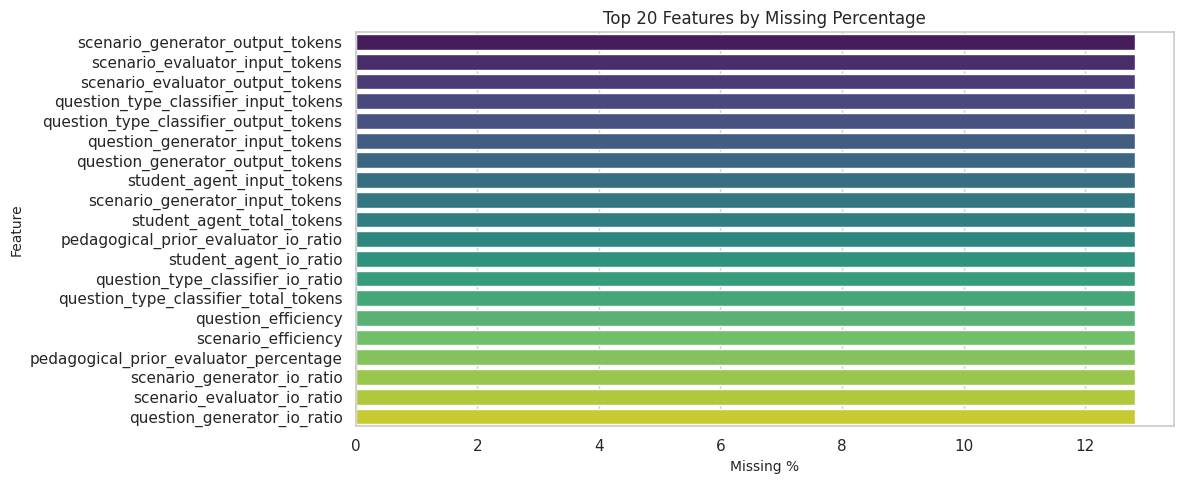

In [39]:
# Missing values and duplicates overview
null_pct = (eda_df.isna().mean() * 100).sort_values(ascending=False)
null_df = null_pct.reset_index()
null_df.columns = ["feature", "null_pct"]

print("Duplicate rows:", eda_df.duplicated().sum())
display(null_df.head(15))

plt.figure(figsize=(12, 5))
sns.barplot(data=null_df.head(20), x="null_pct", y="feature", palette="viridis")
plt.title("Top 20 Features by Missing Percentage")
plt.xlabel("Missing %")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

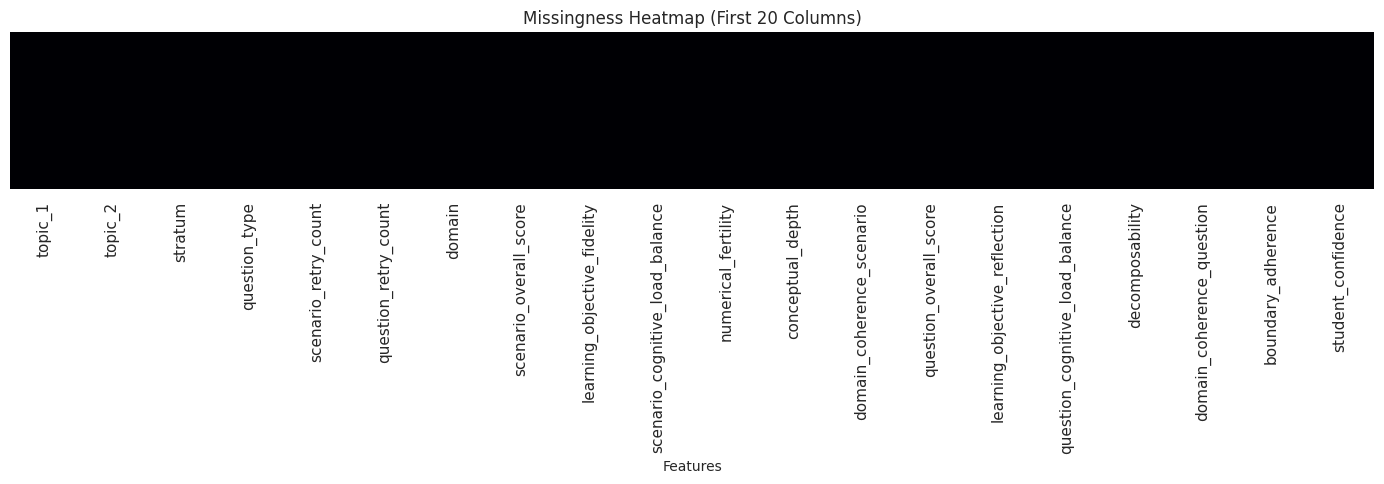

In [40]:
# Missingness map for a compact sample of columns
sample_cols = eda_df.columns[:20]
plt.figure(figsize=(14, 5))
sns.heatmap(eda_df[sample_cols].isnull(), cbar=False, yticklabels=False, cmap="magma")
plt.title("Missingness Heatmap (First 20 Columns)")
plt.xlabel("Features")
plt.tight_layout()
plt.show()

### Insights: Data Quality and Missingness
- Use the missing-percentage bar chart to prioritize imputation or exclusion strategy.
- If missingness clusters by rows, inspect pipeline stages where certain nodes do not return scores.
- If missingness is concentrated in a few columns, model-specific imputation may be enough instead of dropping rows.
- Duplicate count should ideally remain zero for clean run-level analysis.

## EDA Block 3: Univariate Distributions

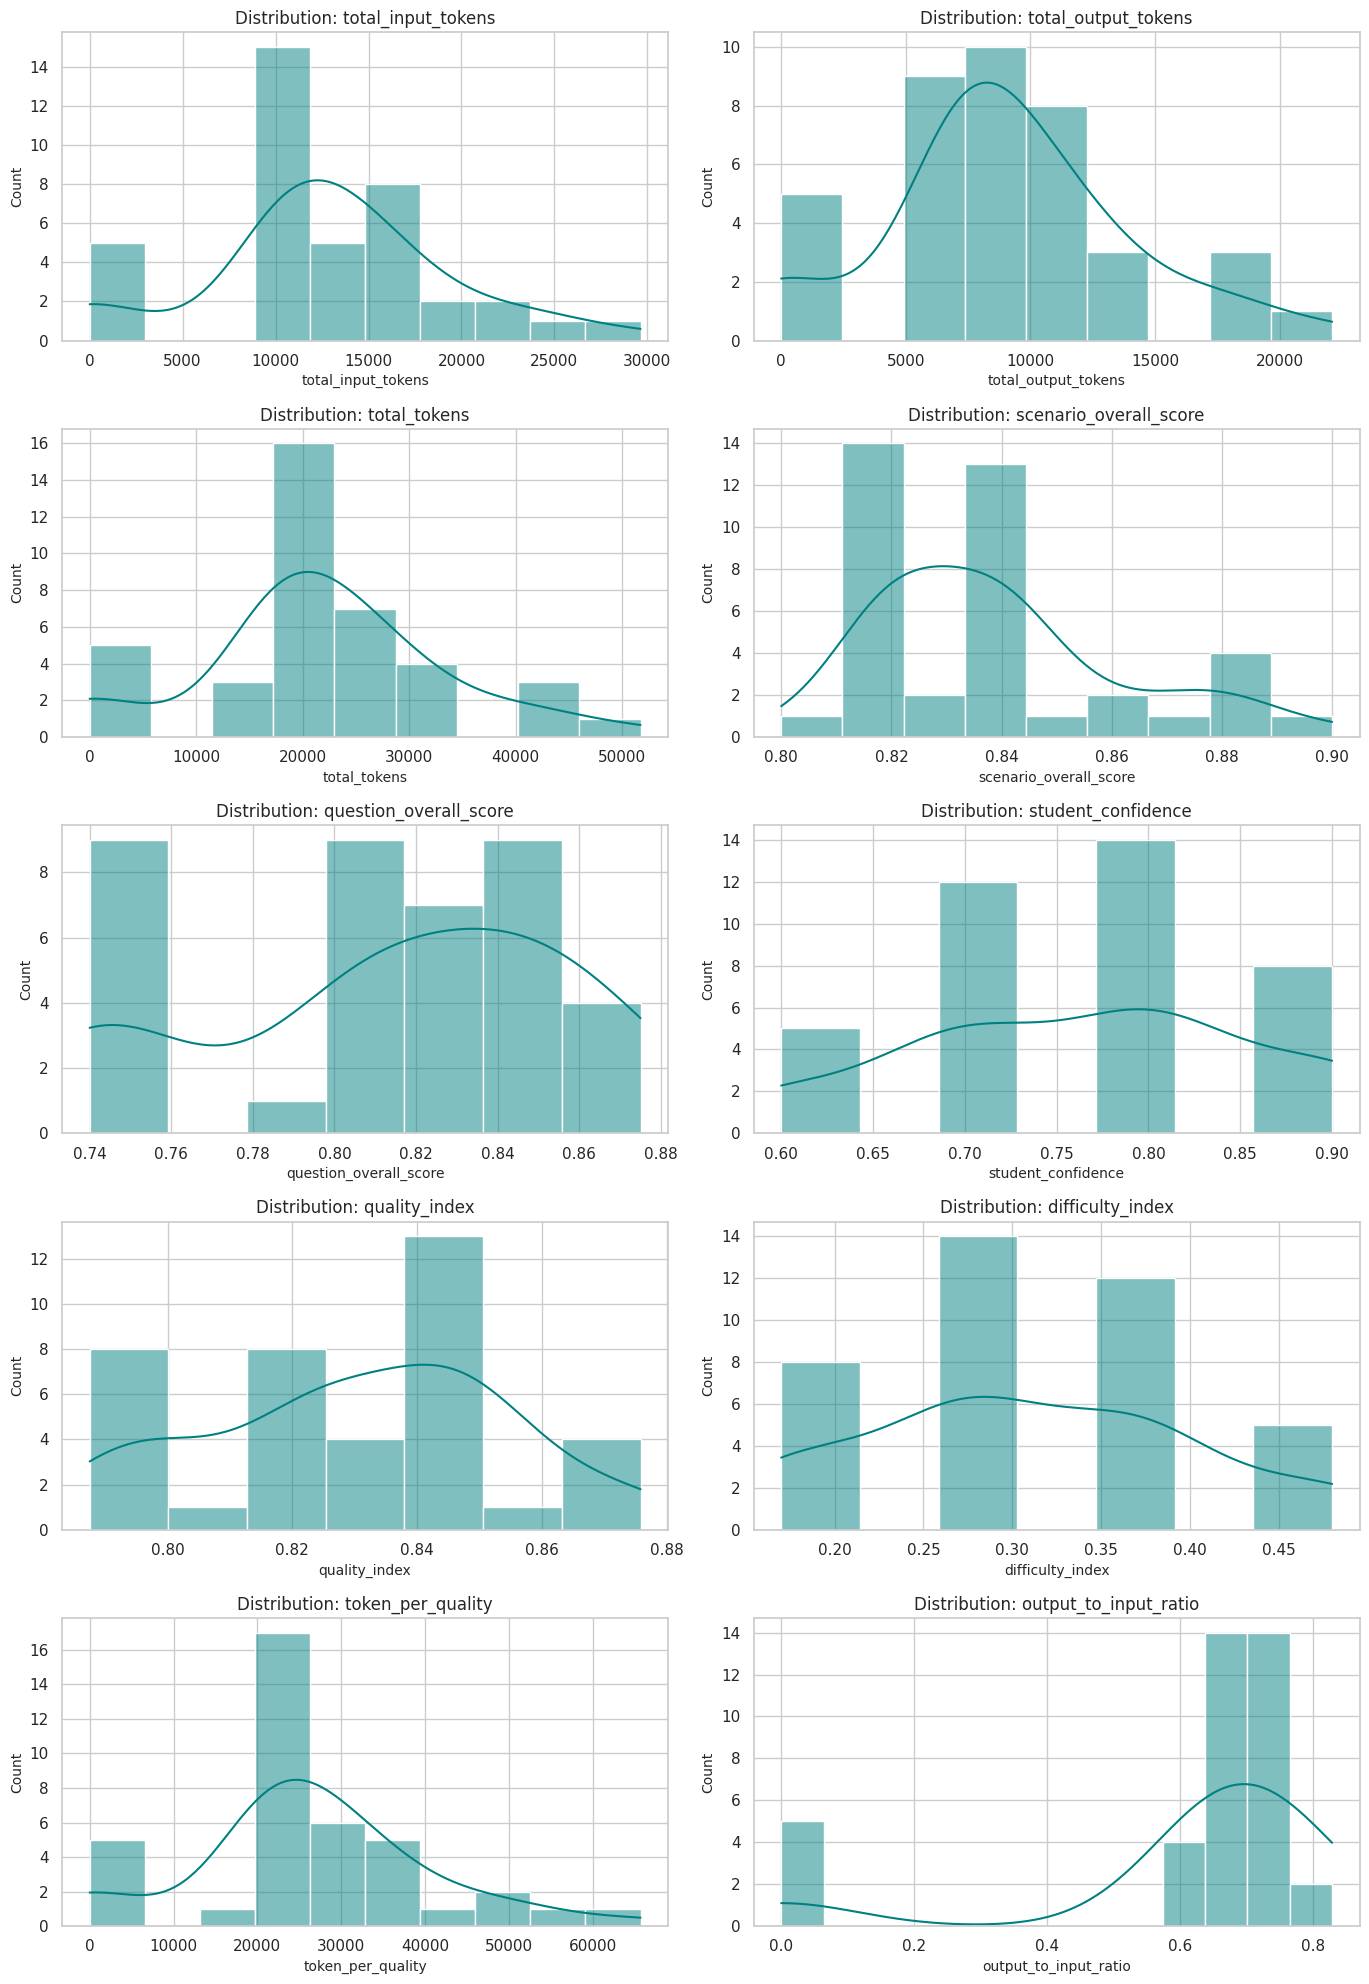

In [41]:
# Histograms for key numeric features
key_numeric = [
    "total_input_tokens", "total_output_tokens", "total_tokens",
    "scenario_overall_score", "question_overall_score",
    "student_confidence", "quality_index", "difficulty_index",
    "token_per_quality", "output_to_input_ratio"
]

valid_key_numeric = [c for c in key_numeric if c in eda_df.columns]

n_cols = 2
n_rows = int(np.ceil(len(valid_key_numeric) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for i, col in enumerate(valid_key_numeric):
    sns.histplot(eda_df[col].dropna(), kde=True, ax=axes[i], color="teal")
    axes[i].set_title(f"Distribution: {col}")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

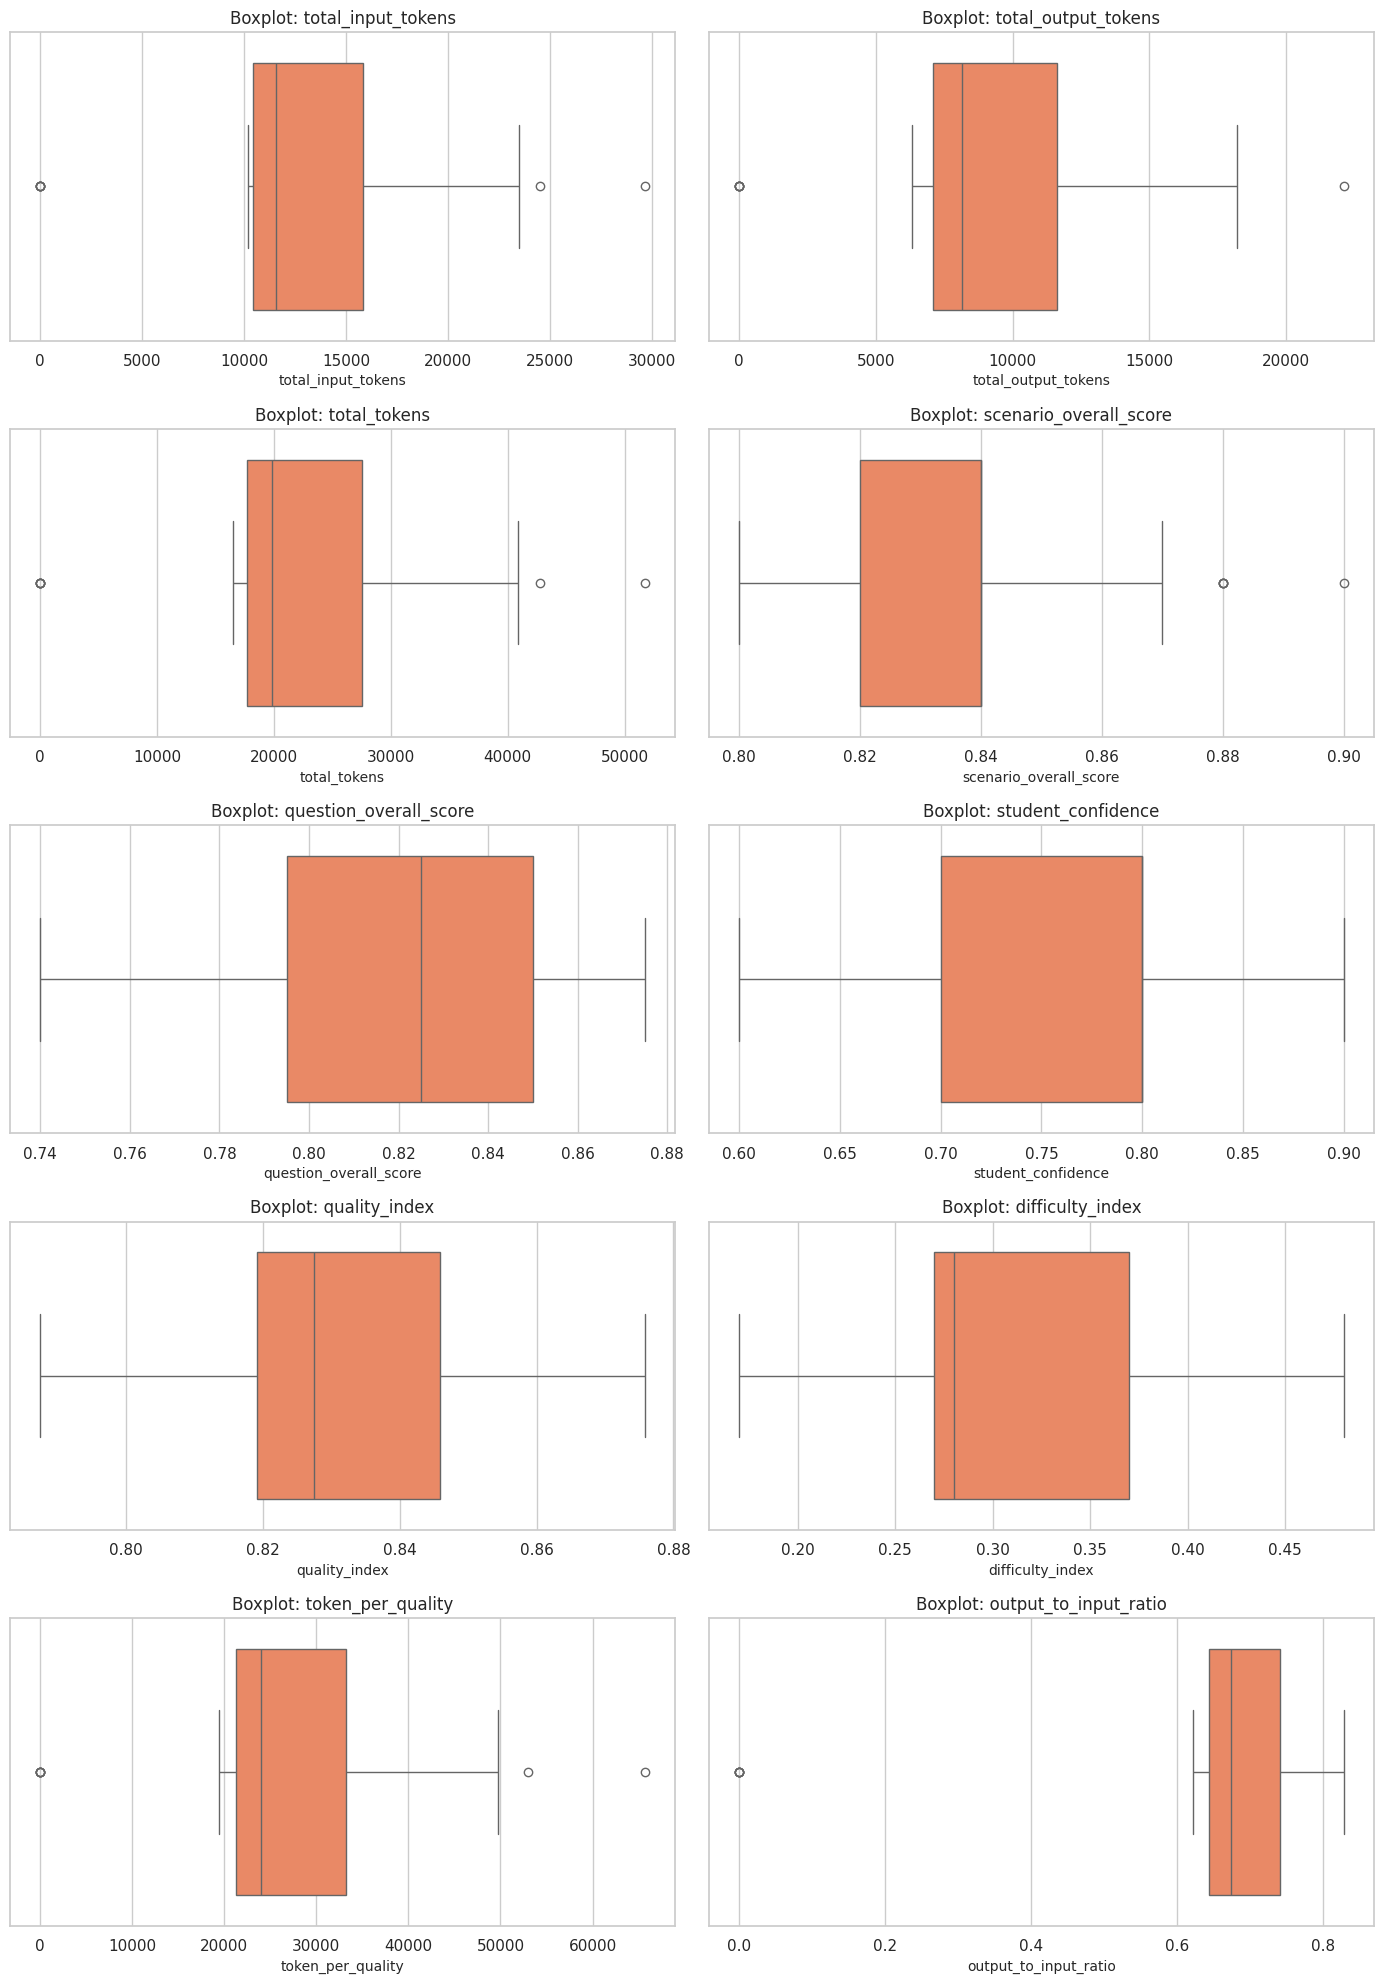

In [42]:
# Boxplots for robust outlier visibility
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for i, col in enumerate(valid_key_numeric):
    sns.boxplot(x=eda_df[col], ax=axes[i], color="coral")
    axes[i].set_title(f"Boxplot: {col}")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Insights: Univariate Distributions
- Token metrics are typically right-skewed; prefer median/IQR over mean/std when summarizing costs.
- If `token_per_quality` has a long right tail, a few runs are disproportionately expensive relative to quality.
- Outliers in `difficulty_index` highlight potentially under-scaffolded or ambiguous questions.
- Check whether score columns are compressed in a narrow range, which may reduce model discrimination power.

## EDA Block 4: Categorical and Segment Analysis

/tmp/ipykernel_111756/3667924292.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=eda_df, x=col, order=order, palette="Set2")


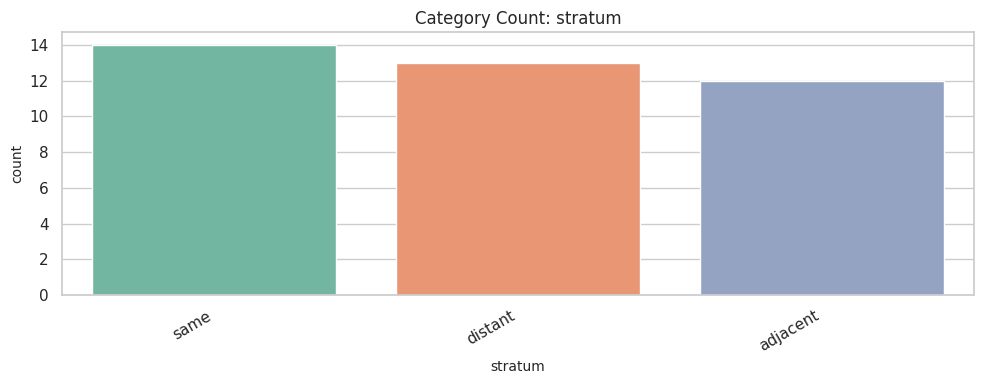

/tmp/ipykernel_111756/3667924292.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=eda_df, x=col, order=order, palette="Set2")


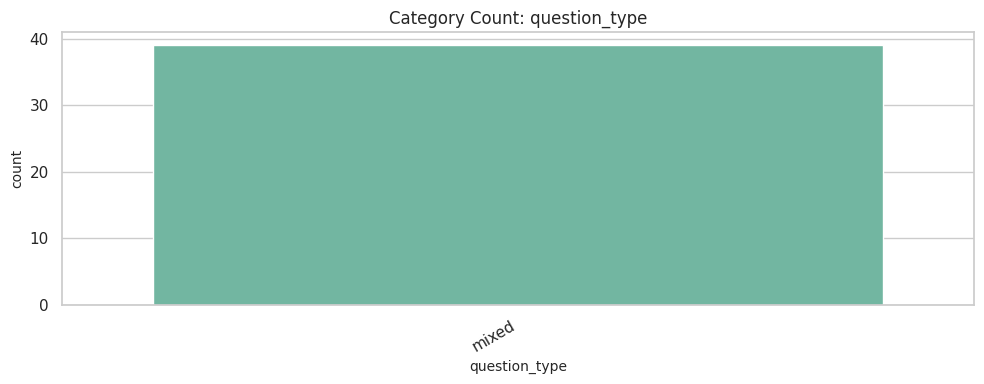

/tmp/ipykernel_111756/3667924292.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=eda_df, x=col, order=order, palette="Set2")


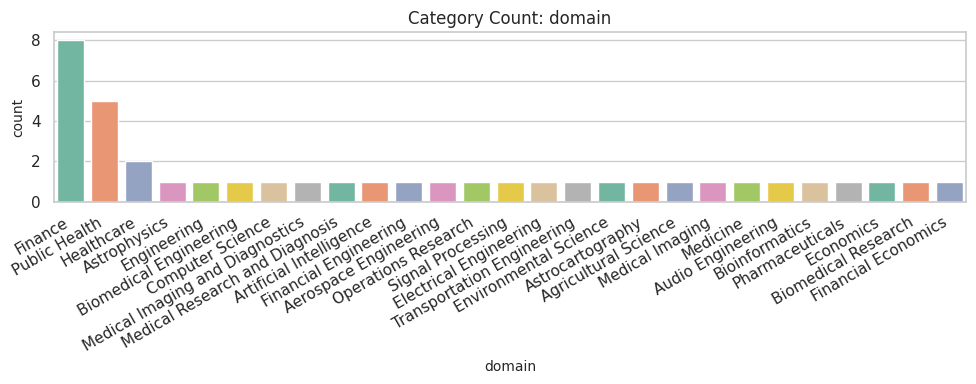

/tmp/ipykernel_111756/3667924292.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=eda_df, x=col, order=order, palette="Set2")


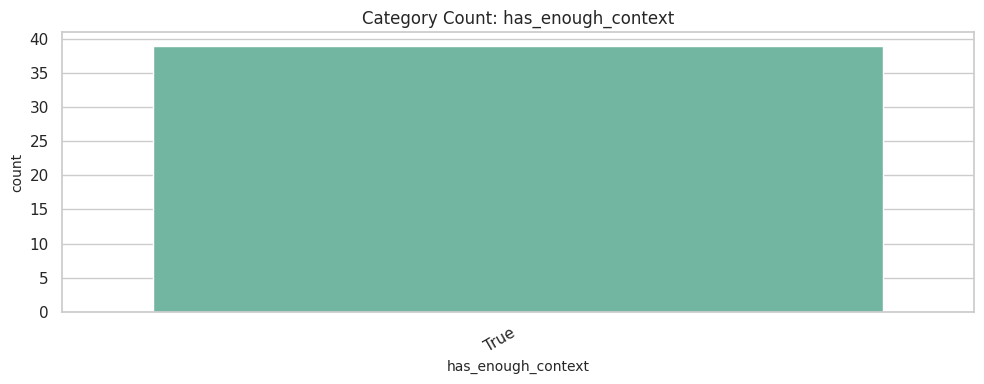

/tmp/ipykernel_111756/3667924292.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=eda_df, x=col, order=order, palette="Set2")


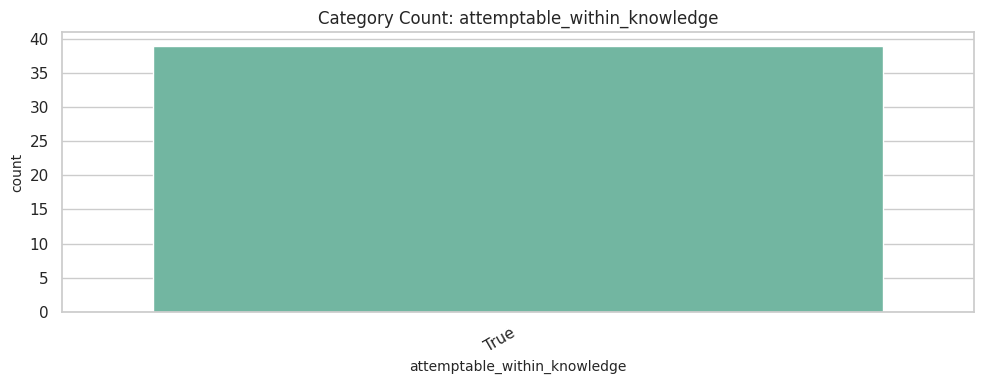

/tmp/ipykernel_111756/3667924292.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=eda_df, x=col, order=order, palette="Set2")


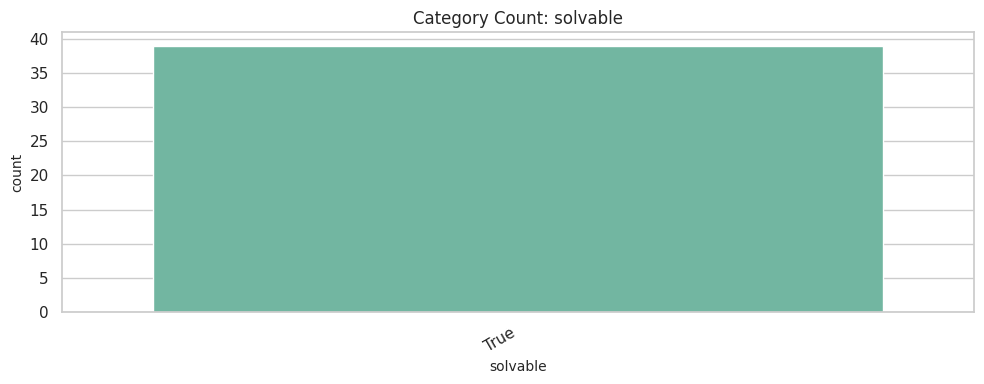

In [43]:
# Count plots for categorical fields if present
categorical_candidates = ["stratum", "question_type", "domain", "has_enough_context", "attemptable_within_knowledge", "solvable"]
cat_cols = [c for c in categorical_candidates if c in eda_df.columns]

for col in cat_cols:
    plt.figure(figsize=(10, 4))
    order = eda_df[col].astype(str).value_counts().index
    sns.countplot(data=eda_df, x=col, order=order, palette="Set2")
    plt.title(f"Category Count: {col}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_111756/2036596523.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=eda_df, x=segment_col, y=metric, palette="Spectral")


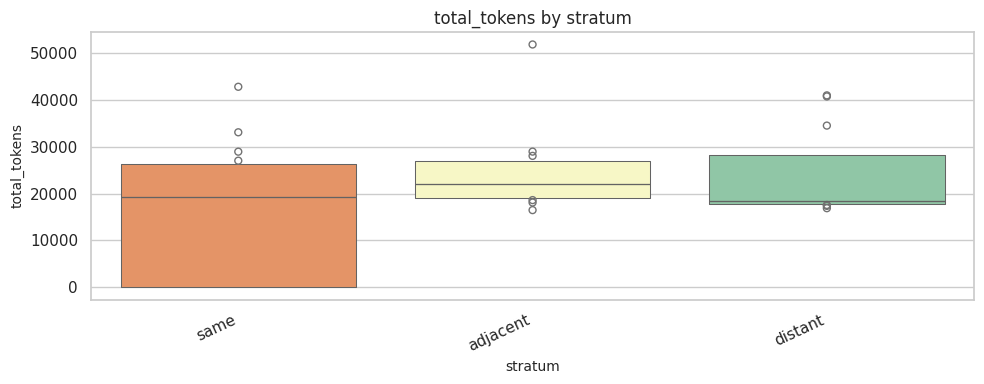

/tmp/ipykernel_111756/2036596523.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=eda_df, x=segment_col, y=metric, palette="Spectral")


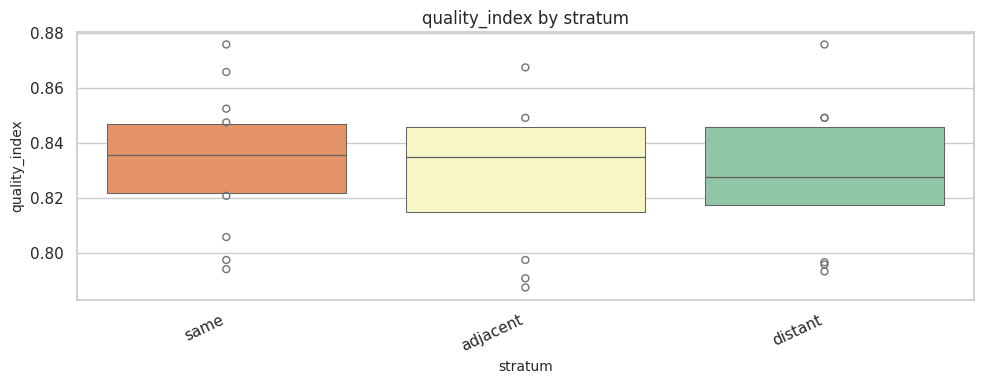

/tmp/ipykernel_111756/2036596523.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=eda_df, x=segment_col, y=metric, palette="Spectral")


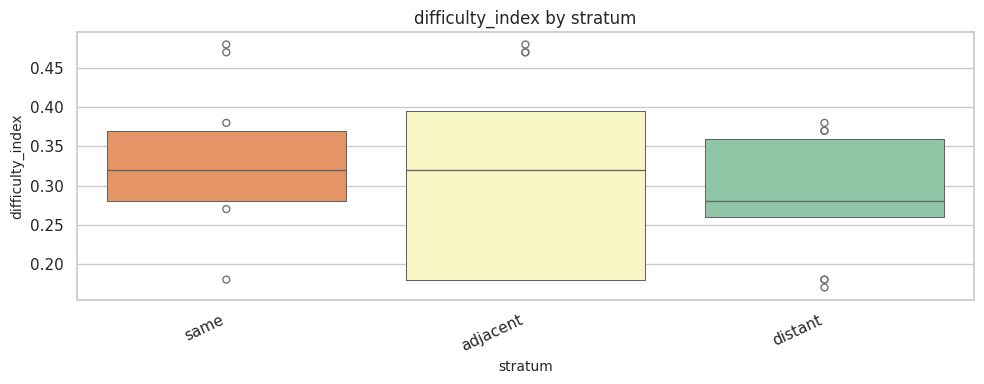

/tmp/ipykernel_111756/2036596523.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=eda_df, x=segment_col, y=metric, palette="Spectral")


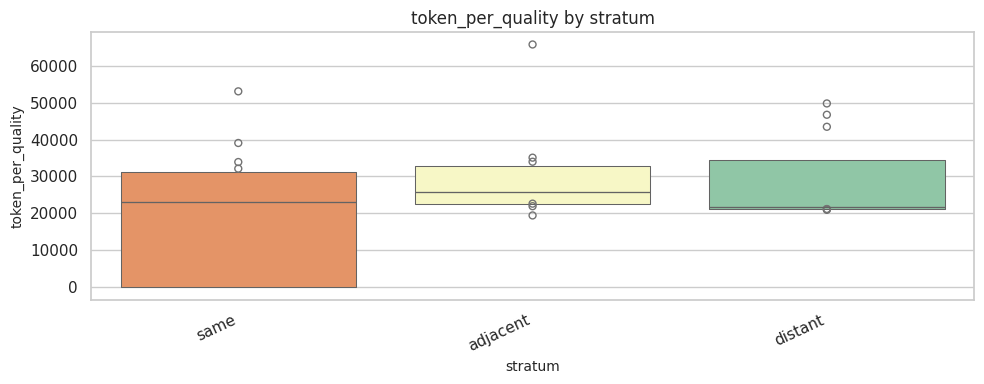

In [44]:
# Segment-level distributions for key metrics
segment_col = "stratum" if "stratum" in eda_df.columns else None
segment_metrics = [c for c in ["total_tokens", "quality_index", "difficulty_index", "token_per_quality"] if c in eda_df.columns]

if segment_col:
    for metric in segment_metrics:
        plt.figure(figsize=(10, 4))
        sns.boxenplot(data=eda_df, x=segment_col, y=metric, palette="Spectral")
        plt.title(f"{metric} by {segment_col}")
        plt.xticks(rotation=25, ha="right")
        plt.tight_layout()
        plt.show()

### Insights: Categorical and Segment Analysis
- Compare median `total_tokens` by `stratum` to identify structurally expensive strata.
- If a stratum has high `difficulty_index` and low `quality_index`, it may need prompt redesign.
- Check whether `solvable=False` concentrates in specific question types or domains.
- Segment-level spread (boxen plots) reveals consistency, not just central tendency.

## EDA Block 5: Correlation and Multivariate Analysis

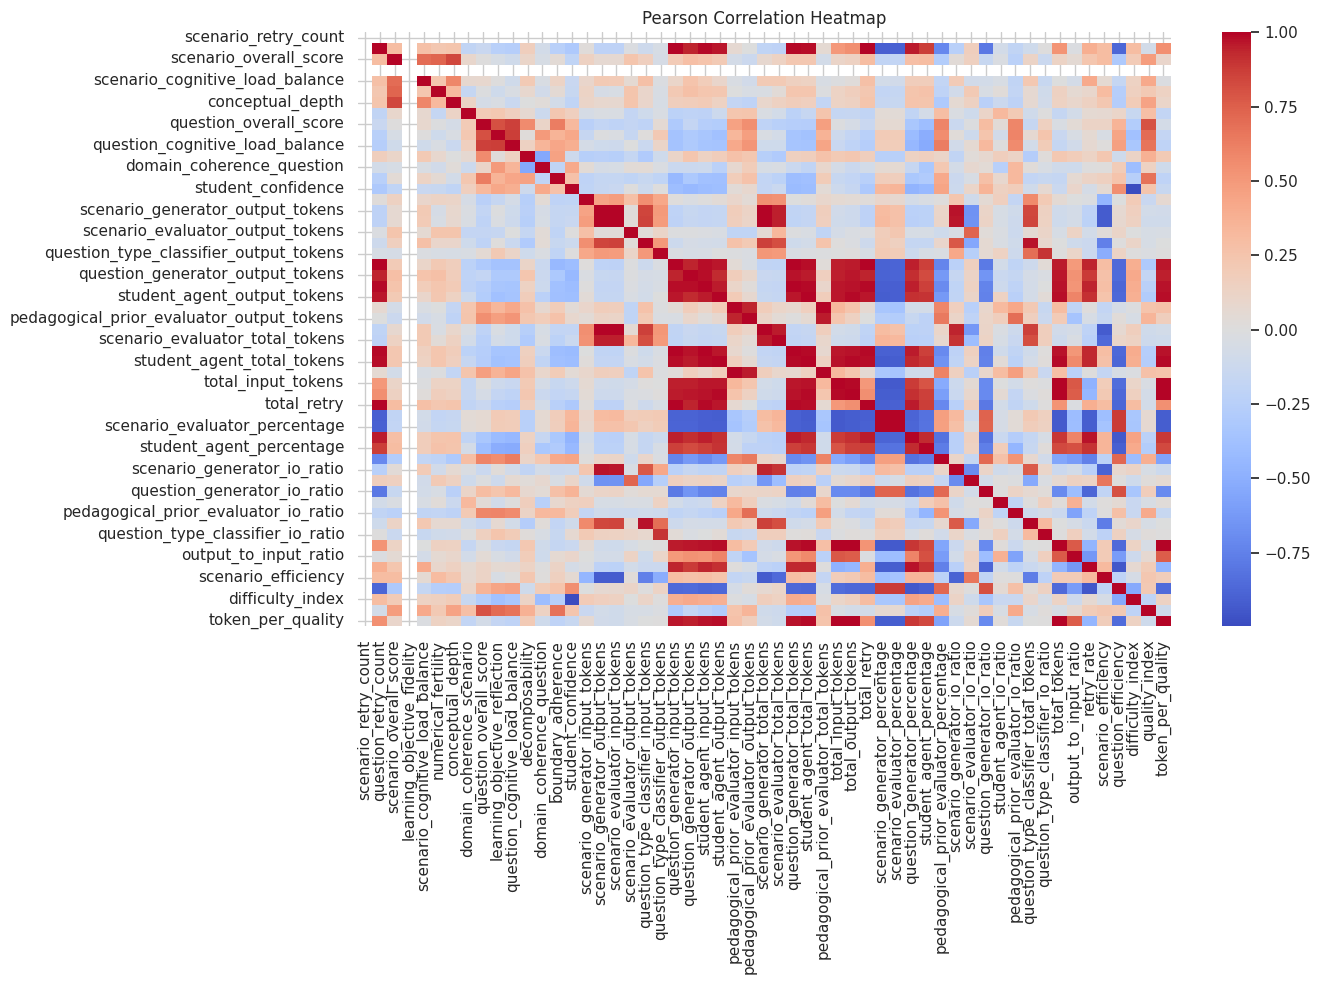

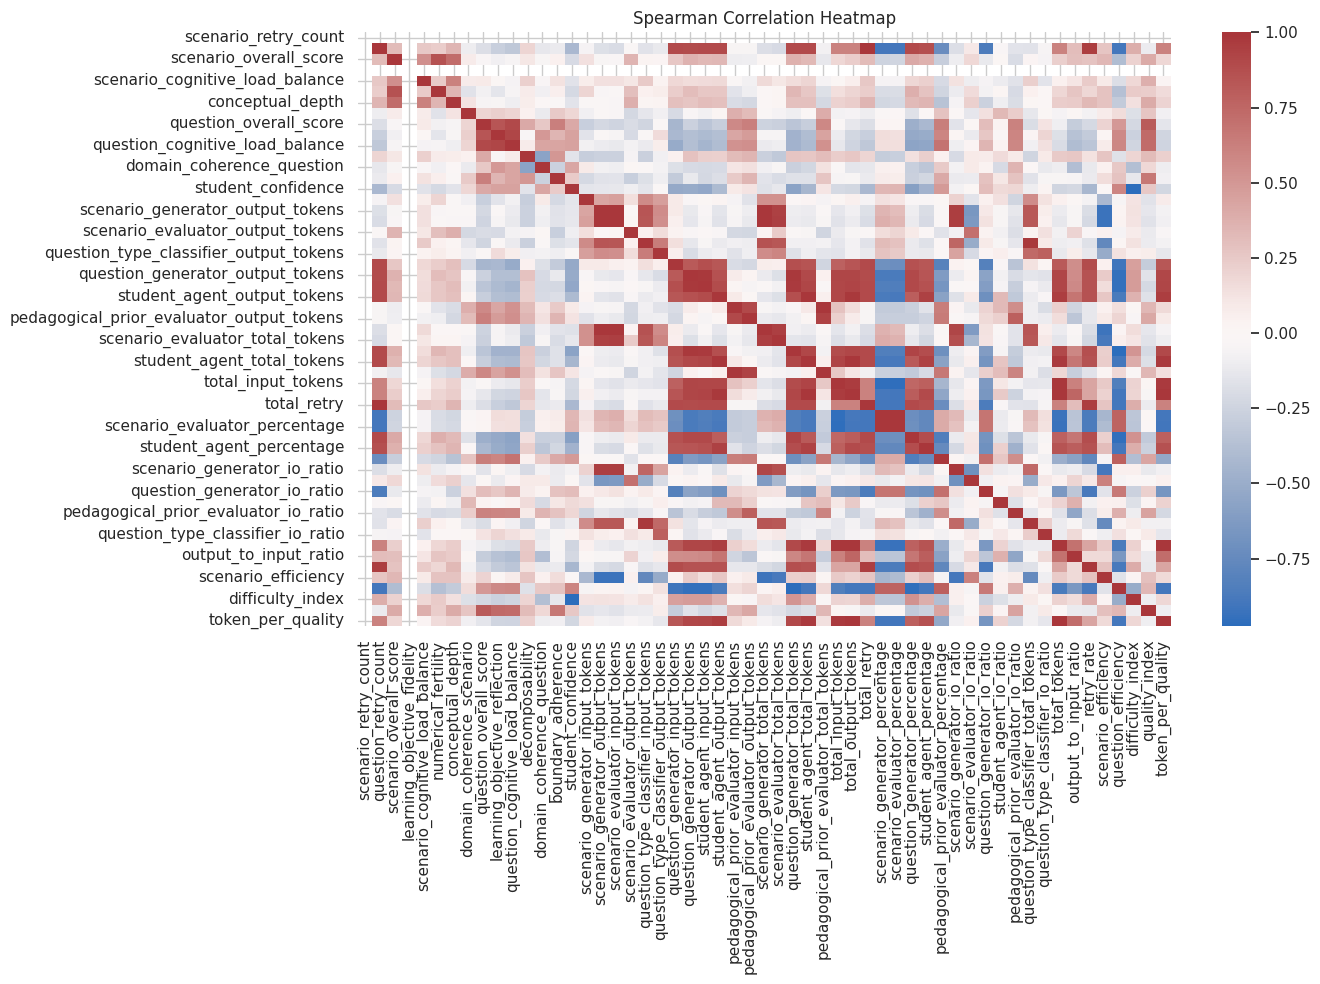

In [45]:
# Correlation heatmaps (Pearson and Spearman)
num_df = eda_df.select_dtypes(include=[np.number]).copy()
num_df = num_df.drop(columns=[c for c in ["id"] if c in num_df.columns])

pearson_corr = num_df.corr(method="pearson")
spearman_corr = num_df.corr(method="spearman")

plt.figure(figsize=(14, 10))
sns.heatmap(pearson_corr, cmap="coolwarm", center=0)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 10))
sns.heatmap(spearman_corr, cmap="vlag", center=0)
plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

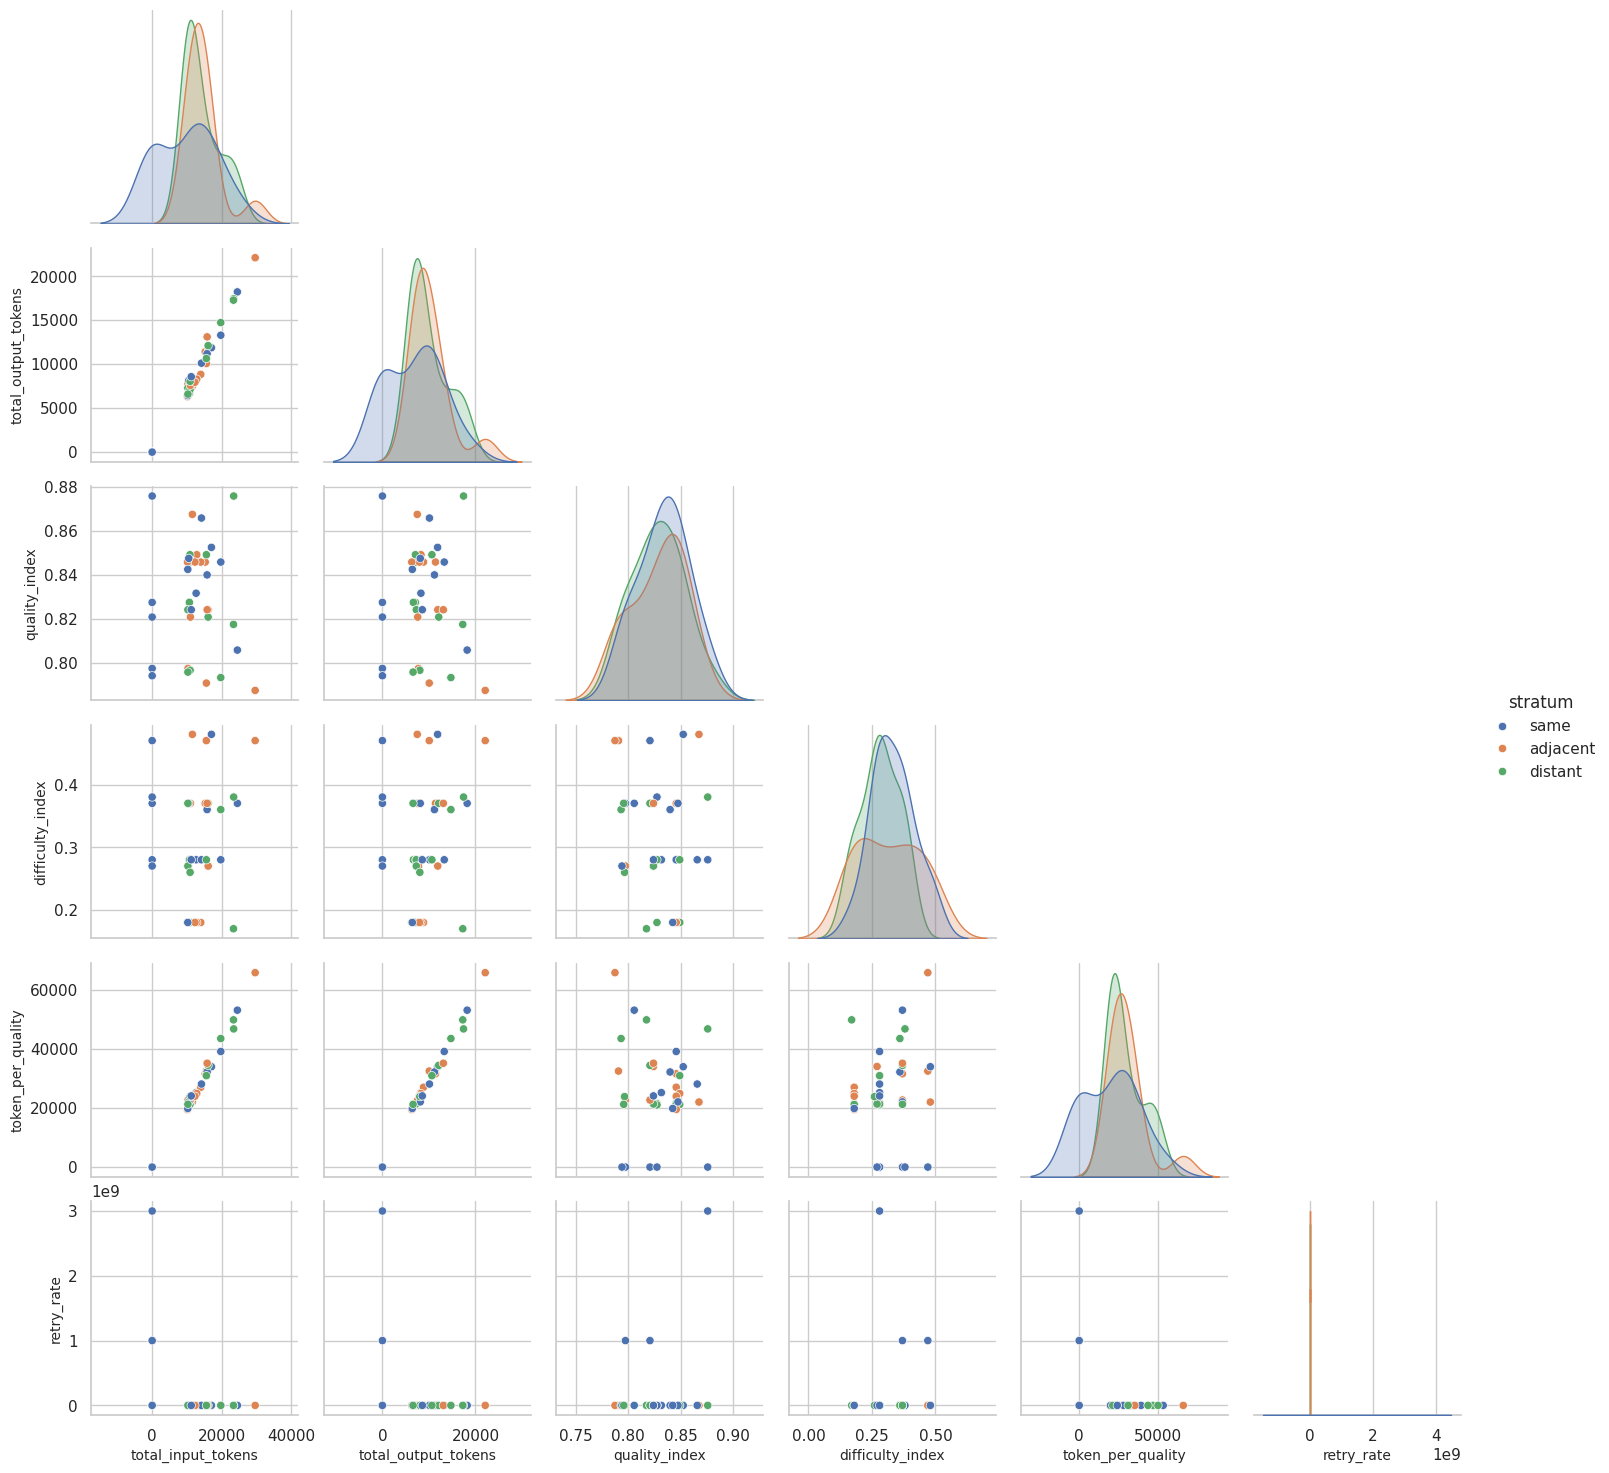

In [46]:
# Pairwise relationships for a focused feature subset
pair_cols = [c for c in ["total_input_tokens", "total_output_tokens", "quality_index", "difficulty_index", "token_per_quality", "retry_rate", "stratum"] if c in eda_df.columns]

if "stratum" in pair_cols:
    sns.pairplot(eda_df[pair_cols].dropna(), hue="stratum", corner=True, diag_kind="kde")
else:
    sns.pairplot(eda_df[pair_cols].dropna(), corner=True, diag_kind="kde")
plt.show()

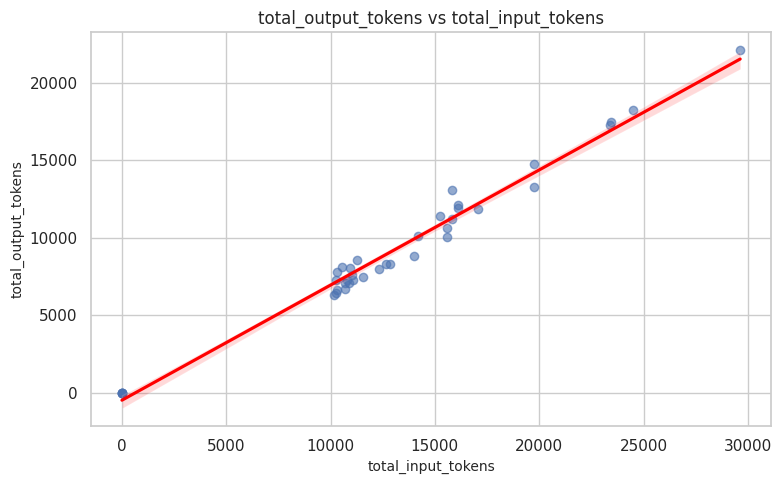

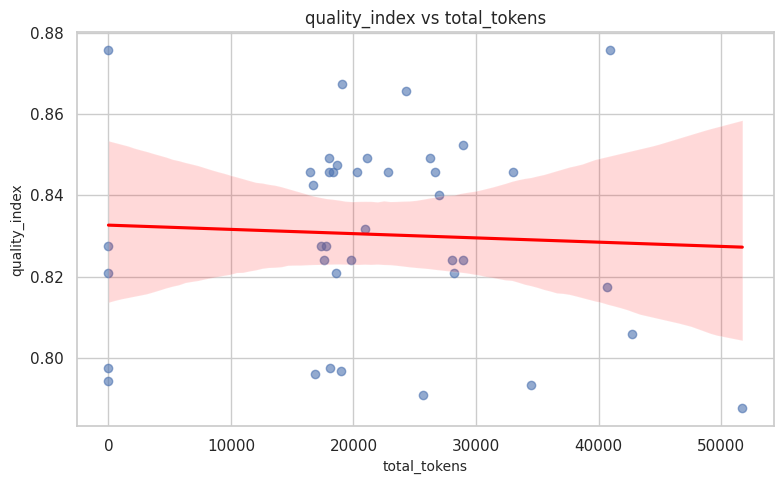

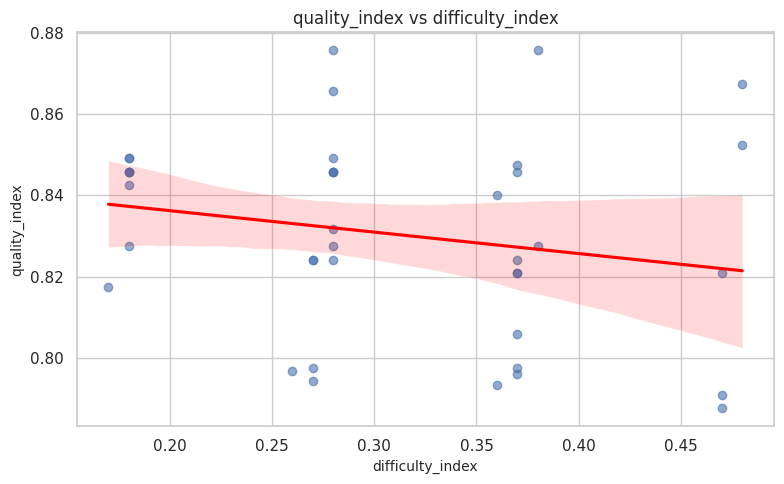

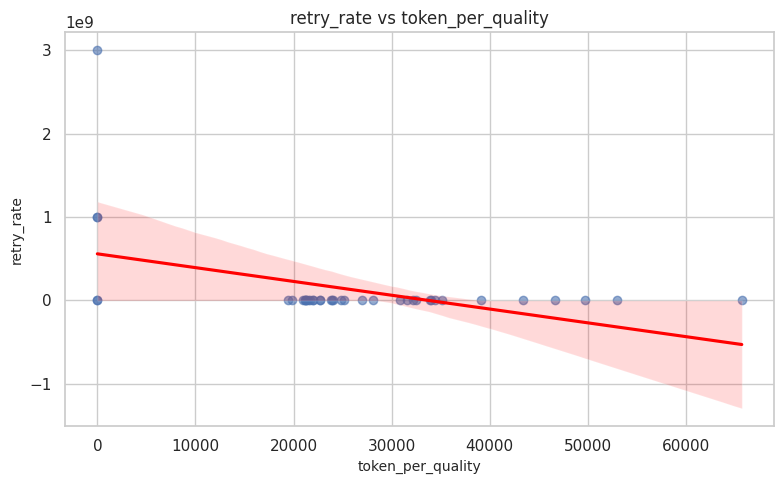

In [47]:
# Targeted bivariate checks with regression lines
bivariate_pairs = [
    ("total_input_tokens", "total_output_tokens"),
    ("total_tokens", "quality_index"),
    ("difficulty_index", "quality_index"),
    ("token_per_quality", "retry_rate"),
]

for x, y in bivariate_pairs:
    if x in eda_df.columns and y in eda_df.columns:
        plt.figure(figsize=(8, 5))
        sns.regplot(data=eda_df, x=x, y=y, scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
        plt.title(f"{y} vs {x}")
        plt.tight_layout()
        plt.show()

### Insights: Correlation and Multivariate Analysis
- Use Pearson for linear relationships and Spearman for monotonic but non-linear tendencies.
- Strong positive `total_input_tokens` vs `total_output_tokens` is expected; inspect residual spread for prompt variability.
- If `token_per_quality` rises with `retry_rate`, retries may be adding cost faster than quality.
- Negative slope between `difficulty_index` and `quality_index` can indicate hard scenarios reducing output quality.

## EDA Block 6: Outliers, Efficiency Ranking, and Actionable Summary

Outlier count distribution:
outlier_count
0    32
2     7
Name: count, dtype: int64


/tmp/ipykernel_111756/729704769.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=eda_df, x="outlier_count", palette="rocket")


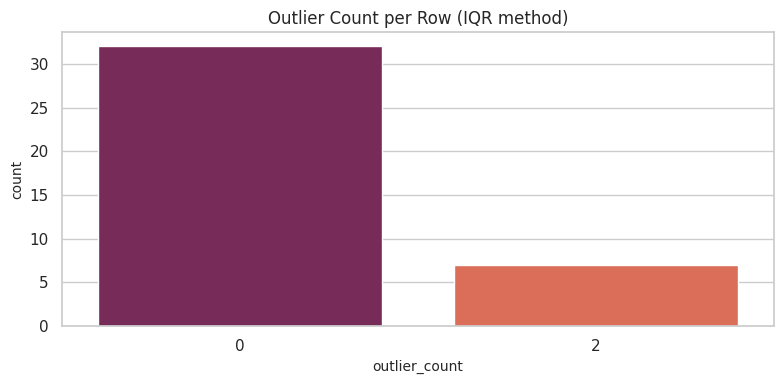

In [48]:
# IQR-based outlier flagging on key cost and quality features
outlier_features = [c for c in ["total_tokens", "token_per_quality", "difficulty_index", "quality_index"] if c in eda_df.columns]
outlier_flags = pd.DataFrame(index=eda_df.index)

for col in outlier_features:
    q1 = eda_df[col].quantile(0.25)
    q3 = eda_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_flags[col + "_outlier"] = (eda_df[col] < lower) | (eda_df[col] > upper)

outlier_flags["outlier_count"] = outlier_flags.sum(axis=1)
eda_df["outlier_count"] = outlier_flags["outlier_count"]

print("Outlier count distribution:")
print(eda_df["outlier_count"].value_counts().sort_index())

plt.figure(figsize=(8, 4))
sns.countplot(data=eda_df, x="outlier_count", palette="rocket")
plt.title("Outlier Count per Row (IQR method)")
plt.tight_layout()
plt.show()

In [49]:
# Most expensive and most efficient runs
rank_cols = [c for c in ["id", "topic_1", "topic_2", "stratum", "total_tokens", "quality_index", "token_per_quality", "retry_rate"] if c in eda_df.columns]

most_expensive = eda_df.sort_values("total_tokens", ascending=False)[rank_cols].head(10)
most_efficient = eda_df.sort_values("token_per_quality", ascending=True)[rank_cols].head(10)

print("Top 10 Most Expensive Runs")
display(most_expensive)
print("Top 10 Most Efficient Runs (Lower token_per_quality is better)")
display(most_efficient)

Top 10 Most Expensive Runs


,id,topic_1,topic_2,stratum,total_tokens,quality_index,token_per_quality,retry_rate
12,12,rank_and_null_space,rate_of_change_and_related_rates,adjacent,51734.0,0.787500,65693.968171,0.000058
2,2,eigenvalues_and_eigenvectors,covariance_matrix,same,42728.0,0.805833,53023.371185,0.000070
8,8,markov_chains,bayesian_updating,distant,40898.0,0.875833,46696.098900,0.000049
19,19,linear_transformations,type_i_and_type_ii_errors,distant,40672.0,0.817500,49751.681896,0.000074
29,29,matrix_decomposition_svd,random_variables_and_distributions,distant,34464.0,0.793333,43442.016752,0.000058
26,26,regression_analysis,type_i_and_type_ii_errors,same,33038.0,0.845833,39059.704387,0.000030
27,27,optimization_maxima_and_minima,information_theory_and_entropy,adjacent,28922.0,0.824167,35092.416540,0.000035
20,20,bayes_theorem,information_theory_and_entropy,same,28910.0,0.852500,33912.023421,0.000035
25,25,multivariable_optimization,random_variables_and_distributions,distant,28212.0,0.820833,34369.949197,0.000035
11,11,correlation_vs_causation,expected_value,adjacent,28016.0,0.824167,33993.124327,0.000036


Top 10 Most Efficient Runs (Lower token_per_quality is better)


,id,topic_1,topic_2,stratum,total_tokens,quality_index,token_per_quality,retry_rate
0,0,vector_spaces_and_subspaces,determinants_and_invertibility,same,0.0,0.797500,0.000000,1.000000e+09
13,13,integration_and_area_under_curve,multivariable_optimization,same,0.0,0.820833,0.000000,1.000000e+09
28,28,eigenvalues_and_eigenvectors,markov_chains,same,0.0,0.875833,0.000000,3.000000e+09
22,22,differential_equations_odes,integration_and_area_under_curve,same,0.0,0.827500,0.000000,0.000000e+00
36,36,law_of_large_numbers,monte_carlo_simulation,same,0.0,0.794167,0.000000,0.000000e+00
32,32,linear_transformations,variance_and_standard_deviation,adjacent,16468.0,0.845833,19469.556627,0.000000e+00
34,34,eigenvalues_and_eigenvectors,determinants_and_invertibility,same,16682.0,0.842500,19800.593448,0.000000e+00
7,7,determinants_and_invertibility,confidence_intervals,distant,17370.0,0.827500,20990.936531,0.000000e+00
18,18,gradient_and_partial_derivatives,expected_value,distant,17966.0,0.849167,21157.212929,0.000000e+00
37,37,rank_and_null_space,anova_variance_analysis,distant,16876.0,0.795833,21205.445000,0.000000e+00


In [50]:
# Topic pair level summary (where available)
group_cols = [c for c in ["topic_1", "topic_2"] if c in eda_df.columns]
if len(group_cols) == 2:
    topic_summary = (
        eda_df.groupby(group_cols, dropna=False)
        .agg(
            runs=("id", "count"),
            mean_total_tokens=("total_tokens", "mean"),
            mean_quality=("quality_index", "mean"),
            mean_retry_rate=("retry_rate", "mean"),
            mean_difficulty=("difficulty_index", "mean"),
        )
        .reset_index()
        .sort_values("mean_total_tokens", ascending=False)
    )

    print("Top topic pairs by mean total token usage")
    display(topic_summary.head(15))

Top topic pairs by mean total token usage


,topic_1,topic_2,runs,mean_total_tokens,mean_quality,mean_retry_rate,mean_difficulty
34,rank_and_null_space,rate_of_change_and_related_rates,1,51734.0,0.787500,0.000058,0.47
6,eigenvalues_and_eigenvectors,covariance_matrix,1,42728.0,0.805833,0.000070,0.37
24,markov_chains,bayesian_updating,1,40898.0,0.875833,0.000049,0.38
22,linear_transformations,type_i_and_type_ii_errors,1,40672.0,0.817500,0.000074,0.17
26,matrix_decomposition_svd,random_variables_and_distributions,1,34464.0,0.793333,0.000058,0.36
36,regression_analysis,type_i_and_type_ii_errors,1,33038.0,0.845833,0.000030,0.28
29,optimization_maxima_and_minima,information_theory_and_entropy,1,28922.0,0.824167,0.000035,0.37
0,bayes_theorem,information_theory_and_entropy,1,28910.0,0.852500,0.000035,0.48
27,multivariable_optimization,random_variables_and_distributions,1,28212.0,0.820833,0.000035,0.37
2,correlation_vs_causation,expected_value,1,28016.0,0.824167,0.000036,0.27


### Insights: Outliers and Efficiency
- Investigate rows with high `outlier_count`; they are likely prompt/pathological edge-cases.
- Compare `most_expensive` vs `most_efficient` tables to identify prompt structures that scale poorly.
- Topic pairs with high mean tokens but low mean quality are first candidates for optimization.
- A practical objective is minimizing `token_per_quality` while maintaining acceptable solvability and confidence.

## Executive Summary (Fill After Running)
- Cost profile: Identify whether token consumption is dominated by a few high-cost runs or broadly distributed.
- Quality-cost tradeoff: Check whether higher token usage consistently improves `quality_index`.
- Reliability: Use `retry_rate` and solvability flags to detect unstable generation patterns.
- Optimization target: Prioritize reducing expensive prompt segments for strata/topic pairs with weak quality returns.
- Immediate action: Start with scenario/question prompt compactness, then re-check `token_per_quality` and `difficulty_index` shifts.